In [7]:
import networkx as nx

G = nx.Graph()

nodes_dict = {
    'Start': start_pos,
    'Goal': goal_pos,
    'A': (1, 1), 'B': (1, 6), 'C': (1, 12), 'D': (1, 18),
    'E': (13, 1), 'F': (13, 6), 'G': (13, 12), 'H': (13, 18),
    'I': (7, 6), 'J': (7, 12)
}

for name, pos in nodes_dict.items():
    G.add_node(name, pos=pos)

connections = [
    ('Start', 'E'), ('E', 'A'), ('E', 'F'),
    ('A', 'B'), ('B', 'F'), ('B', 'C'),
    ('F', 'I'), ('I', 'B'), ('I', 'G'), ('I', 'J'),
    ('C', 'G'), ('C', 'D'), ('G', 'H'), ('H', 'D'),
    ('J', 'C'), ('J', 'G'),
    ('D', 'Goal'), ('H', 'Goal')
]

for u, v in connections:
    pos_u = np.array(nodes_dict[u])
    pos_v = np.array(nodes_dict[v])
    dist = np.linalg.norm(pos_u - pos_v)
    G.add_edge(u, v, weight=dist)

print("Topological warehouse roadmap graph constructed.")

Topological warehouse roadmap graph constructed.


In [8]:
graph_shortest_path = nx.shortest_path(G, source='Start', target='Goal', weight='weight')
print(f"Optimal route in graph: {graph_shortest_path}")

Optimal route in graph: ['Start', 'E', 'F', 'B', 'C', 'D', 'Goal']


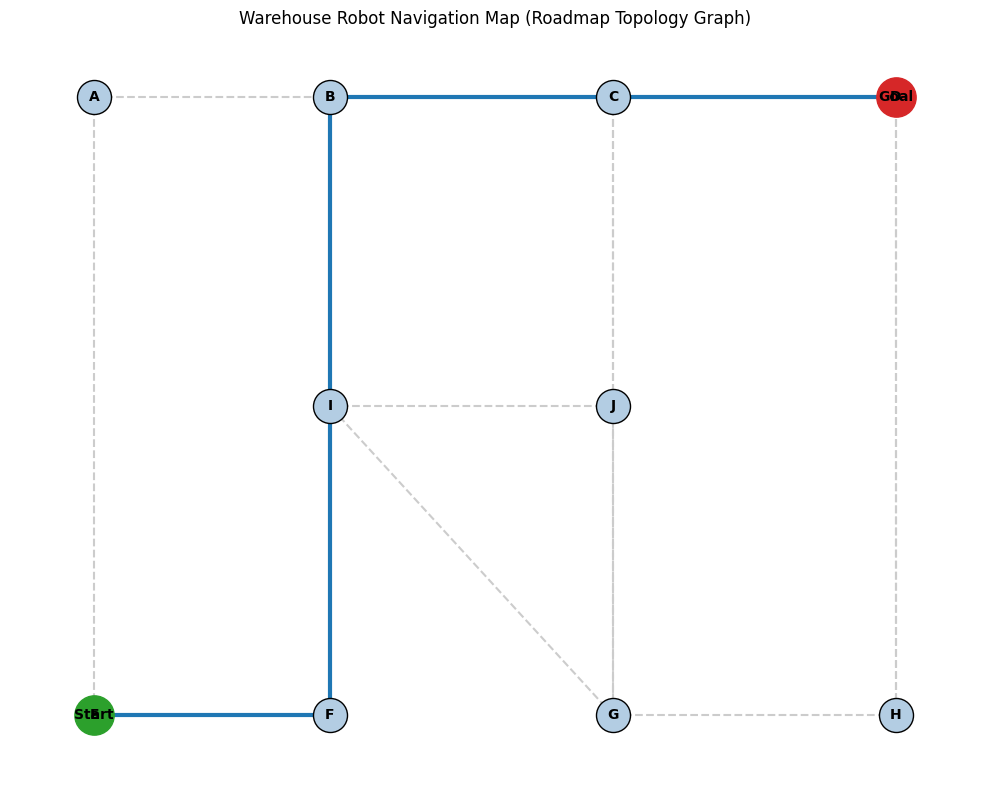

In [9]:
plt.figure(figsize=(10, 8))
pos_layout = {node: (coords[1], -coords[0]) for node, coords in nodes_dict.items()}

nx.draw_networkx_nodes(G, pos_layout, node_color='#b3cde3', node_size=600, edgecolors='black')
nx.draw_networkx_edges(G, pos_layout, width=1.5, edge_color='#cccccc', style='dashed')

nx.draw_networkx_nodes(G, pos_layout, nodelist=['Start'], node_color='#2ca02c', node_size=800)
nx.draw_networkx_nodes(G, pos_layout, nodelist=['Goal'], node_color='#d62728', node_size=800)

path_edges = list(zip(graph_shortest_path, graph_shortest_path[1:]))
nx.draw_networkx_edges(G, pos_layout, edgelist=path_edges, width=3.0, edge_color='#1f77b4')

nx.draw_networkx_labels(G, pos_layout, font_size=10, font_weight='bold')

plt.title("Warehouse Robot Navigation Map (Roadmap Topology Graph)")
plt.axis('off')
plt.tight_layout()
plt.show()